<a href="https://colab.research.google.com/github/eduardozurek/ia/blob/main/_008_redes_neuronales_artificiales/02_MLP_XOR_paso_a_paso.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aprendizaje de XOR con un perceptrón multicapa (2–2–1)

**Objetivo:** estudiar paso a paso la propagación hacia adelante, la pérdida *Log Loss*, la retropropagación y la actualización de los **9 parámetros** (6 pesos y 3 sesgos) de una red con **dos neuronas ocultas**.

Usaremos exclusivamente NumPy para que todos los cálculos sean visibles. Primero realizaremos **una actualización SGD** con un patrón; después entrenaremos con **descenso de gradiente por lotes** para observar cómo la red aprende XOR. Se incluyen gráficas, tablas y controles interactivos opcionales.

> Dos neuronas ocultas son suficientes para representar XOR con una capa oculta; una sola neurona sigmoide oculta no puede construir la frontera no lineal necesaria.

,x1,x2,y
0,0.0,0.0,0.0
1,0.0,1.0,1.0
2,1.0,0.0,1.0
3,1.0,1.0,0.0


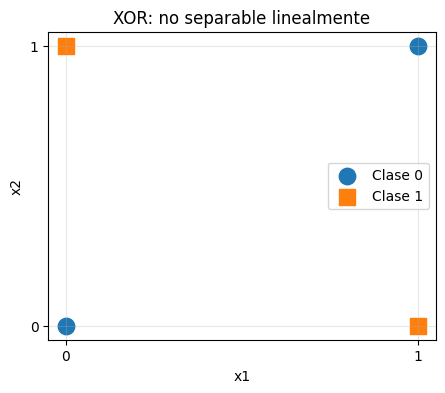

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
np.set_printoptions(precision=6, suppress=True)
X = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
y = np.array([[0.],[1.],[1.],[0.]])
display(pd.DataFrame(np.c_[X,y], columns=['x1','x2','y']))
plt.figure(figsize=(5,4))
plt.scatter(X[y[:,0]==0,0], X[y[:,0]==0,1], s=140, marker='o', label='Clase 0')
plt.scatter(X[y[:,0]==1,0], X[y[:,0]==1,1], s=140, marker='s', label='Clase 1')
plt.xticks([0,1]); plt.yticks([0,1]); plt.xlabel('x1'); plt.ylabel('x2'); plt.title('XOR: no separable linealmente'); plt.legend(); plt.grid(alpha=.3); plt.show()

## 1. Arquitectura y ecuaciones

Cada neurona oculta aplica una sigmoide $\sigma(z)=1/(1+e^{-z})$:

$$Z_1=XW_1+b_1,\qquad H=\sigma(Z_1)$$
$$Z_2=HW_2+b_2,\qquad \hat Y=\sigma(Z_2)$$

Dimensiones: $X:(m,2)$, $W_1:(2,2)$, $b_1:(1,2)$, $W_2:(2,1)$ y $b_2:(1,1)$.

En una sola observación, la pérdida de entropía cruzada binaria es
$$L=-[y\ln(\hat y)+(1-y)\ln(1-\hat y)].$$

Con sigmoide y Log Loss, la señal de error de salida se simplifica a $\delta_2=\hat y-y$.

**Retropropagación:**
$$\frac{\partial L}{\partial W_2}=H^T\delta_2,\qquad \frac{\partial L}{\partial b_2}=\delta_2,$$
$$\delta_1=(\delta_2W_2^T)\odot H\odot(1-H),$$
$$\frac{\partial L}{\partial W_1}=X^T\delta_1,\qquad \frac{\partial L}{\partial b_1}=\delta_1.$$

Para lotes de $m$ observaciones, se promedian los gradientes dividiéndolos por $m$.

In [12]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def forward(X, p):
    z1 = X @ p['W1'] + p['b1']
    h = sigmoid(z1)
    z2 = h @ p['W2'] + p['b2']
    yh = sigmoid(z2)
    return {'z1':z1, 'h':h, 'z2':z2, 'yh':yh}

def log_loss(y, yh):
    eps = 1e-12
    yh = np.clip(yh, eps, 1-eps)
    return float(np.mean(-(y*np.log(yh)+(1-y)*np.log(1-yh))))

def backward(X, y, p, cache):
    m = len(X)
    d2 = (cache['yh']-y) / m
    dW2 = cache['h'].T @ d2
    db2 = d2.sum(axis=0, keepdims=True)
    d1 = (d2 @ p['W2'].T) * cache['h'] * (1-cache['h'])
    dW1 = X.T @ d1
    db1 = d1.sum(axis=0, keepdims=True)
    return {'W1':dW1, 'b1':db1, 'W2':dW2, 'b2':db2}, {'d2':d2,'d1':d1}

def update(p, grad, eta):
    return {k:p[k]-eta*grad[k] for k in p}

# Disposición: columnas de W1 = neuronas ocultas; filas = entradas.
p0 = {'W1':np.array([[.5,-.4],[.3,.2]]),
      'b1':np.array([[.1,-.1]]),
      'W2':np.array([[.7],[-.5]]),
      'b2':np.array([[.2]])}
print('Pesos iniciales W1:\n',p0['W1'])
print('Pesos iniciales W2:\n',p0['W2'])

Pesos iniciales W1:
 [[ 0.5 -0.4]
 [ 0.3  0.2]]
Pesos iniciales W2:
 [[ 0.7]
 [-0.5]]


## 2. Una iteración completamente explicada (SGD)

Tomamos la observación **(0, 1) → 1**, tasa de aprendizaje $\eta=0.5$. Se imprimen los valores intermedios y todos los parámetros antes y después del ajuste.

In [13]:
xi = X[1:2]; yi = y[1:2]; eta = 0.5
c = forward(xi,p0)
g, deltas = backward(xi,yi,p0,c)
p1 = update(p0,g,eta)
for name, val in [('Entrada X',xi),('Objetivo y',yi),('z ocultas',c['z1']),
                  ('Activaciones h',c['h']),('z salida',c['z2']),('Predicción',c['yh']),
                  ('Log Loss antes',log_loss(yi,c['yh'])),('delta salida',deltas['d2']),
                  ('delta ocultas',deltas['d1'])]:
    print(f'{name}:\n{val}\n')
rows=[]
for k in p0:
    for ix in np.ndindex(p0[k].shape):
        rows.append([f'{k}{ix}',p0[k][ix],g[k][ix],p1[k][ix]])
display(pd.DataFrame(rows,columns=['Parámetro','Antes','Gradiente','Después']).round(6))
print('Predicción después:',forward(xi,p1)['yh'][0,0])
print('Log Loss después:',log_loss(yi,forward(xi,p1)['yh']))
print('Nota: con x1=0, las dos derivadas de W1 asociadas a x1 son cero.')

Entrada X:
[[0. 1.]]

Objetivo y:
[[1.]]

z ocultas:
[[0.4 0.1]]

Activaciones h:
[[0.598688 0.524979]]

z salida:
[[0.356592]]

Predicción:
[[0.588215]]

Log Loss antes:
0.5306625006762754

delta salida:
[[-0.411785]]

delta ocultas:
[[-0.069255  0.051345]]



,Parámetro,Antes,Gradiente,Después
0,"W1(0, 0)",0.5,0.000000,0.500000
1,"W1(0, 1)",-0.4,0.000000,-0.400000
2,"W1(1, 0)",0.3,-0.069255,0.334628
3,"W1(1, 1)",0.2,0.051345,0.174328
4,"b1(0, 0)",0.1,-0.069255,0.134628
5,"b1(0, 1)",-0.1,0.051345,-0.125672
6,"W2(0, 0)",0.7,-0.246531,0.823265
7,"W2(1, 0)",-0.5,-0.216178,-0.391911
8,"b2(0, 0)",0.2,-0.411785,0.405892


Predicción después: 0.6707655881020856
Log Loss después: 0.3993355501371472
Nota: con x1=0, las dos derivadas de W1 asociadas a x1 son cero.


## 3. Verificación numérica de los gradientes

Comparamos cada derivada analítica con diferencias finitas centrales. Esto permite comprobar que la retropropagación está bien implementada.

In [14]:
eps = 1e-5
check=[]
for k in p0:
    for ix in np.ndindex(p0[k].shape):
        pa={q:v.copy() for q,v in p0.items()}
        pb={q:v.copy() for q,v in p0.items()}
        pa[k][ix]+=eps; pb[k][ix]-=eps
        num=(log_loss(yi,forward(xi,pa)['yh'])-log_loss(yi,forward(xi,pb)['yh']))/(2*eps)
        check.append((f'{k}{ix}',g[k][ix],num,abs(g[k][ix]-num)))
display(pd.DataFrame(check,columns=['Parámetro','Analítico','Numérico','Error absoluto']).round(9))
assert max(row[3] for row in check)<1e-7

,Parámetro,Analítico,Numérico,Error absoluto
0,"W1(0, 0)",0.000000,0.000000,0.0
1,"W1(0, 1)",0.000000,0.000000,0.0
2,"W1(1, 0)",-0.069255,-0.069255,0.0
3,"W1(1, 1)",0.051345,0.051345,0.0
4,"b1(0, 0)",-0.069255,-0.069255,0.0
5,"b1(0, 1)",0.051345,0.051345,0.0
6,"W2(0, 0)",-0.246531,-0.246531,0.0
7,"W2(1, 0)",-0.216178,-0.216178,0.0
8,"b2(0, 0)",-0.411785,-0.411785,0.0


## 4. Entrenamiento con los cuatro patrones

En esta sección empleamos descenso de gradiente **por lotes** (*batch gradient descent*): cada época calcula el promedio de los gradientes sobre los cuatro ejemplos y actualiza una vez los parámetros. Se usa una inicialización reproducible, diferente de la demostración manual anterior, para evitar una trayectoria de aprendizaje excesivamente lenta.

Guardamos una copia de los pesos de cada época para poder inspeccionar su evolución.

,x1,x2,y real,Probabilidad,Predicción
0,0.0,0.0,0.0,0.00525,0.0
1,0.0,1.0,1.0,0.99280,1.0
2,1.0,0.0,1.0,0.99523,1.0
3,1.0,1.0,0.0,0.00451,0.0


Log Loss inicial: 0.682067; final: 0.005448
Accuracy final: 1.0


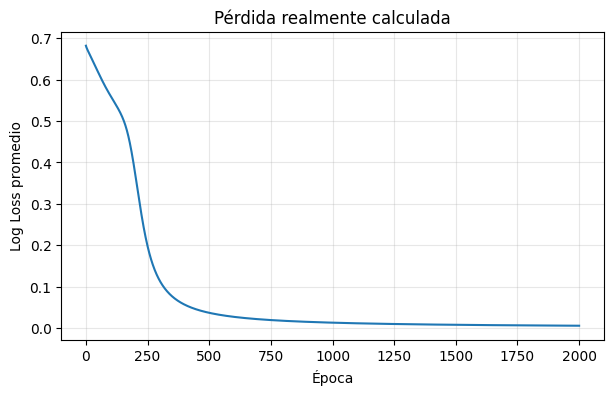

In [15]:
def train(seed=7, eta=1.0, epochs=2000):
    rng=np.random.default_rng(seed)
    p={'W1':rng.normal(0,2.0,(2,2)),
       'b1':rng.normal(0,1.0,(1,2)),
       'W2':rng.normal(0,2.0,(2,1)),
       'b2':rng.normal(0,1.0,(1,1))}
    hist=[]; losses=[]
    for epoch in range(epochs+1):
        cache=forward(X,p)
        losses.append(log_loss(y,cache['yh']))
        hist.append({k:v.copy() for k,v in p.items()})
        if epoch<epochs:
            grad,_=backward(X,y,p,cache)
            p=update(p,grad,eta)
    return p,np.array(losses),hist

p_final, losses, history = train()
result=forward(X,p_final)['yh']
display(pd.DataFrame(np.c_[X,y,result,(result>=.5).astype(int)],
                     columns=['x1','x2','y real','Probabilidad','Predicción']).round(5))
print(f'Log Loss inicial: {losses[0]:.6f}; final: {losses[-1]:.6f}')
print('Accuracy final:',np.mean((result>=.5)==y))
assert np.array_equal((result>=.5).astype(int),y.astype(int)), 'Ajusta semilla/épocas si no converge.'
plt.figure(figsize=(7,4)); plt.plot(losses); plt.xlabel('Época'); plt.ylabel('Log Loss promedio'); plt.title('Pérdida realmente calculada'); plt.grid(alpha=.3); plt.show()

## 5. Evolución de los nueve parámetros

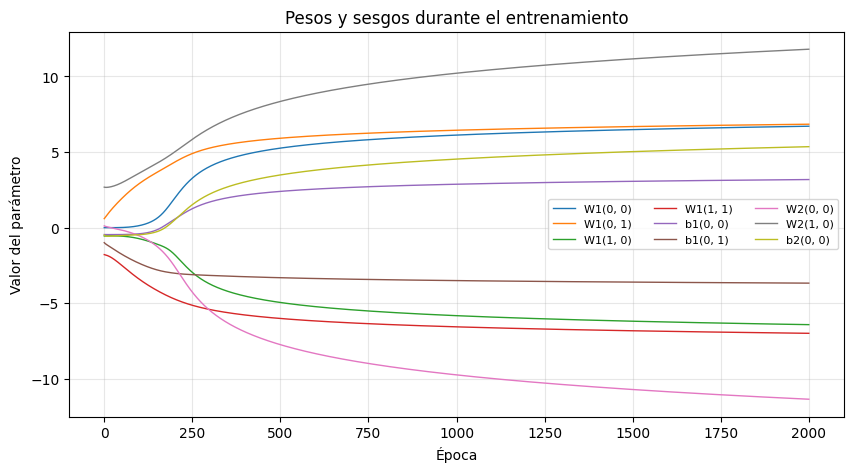

In [16]:
plt.figure(figsize=(10,5))
for k in history[0]:
    for ix in np.ndindex(history[0][k].shape):
        plt.plot([p[k][ix] for p in history],label=f'{k}{ix}',lw=1)
plt.xlabel('Época');plt.ylabel('Valor del parámetro');plt.title('Pesos y sesgos durante el entrenamiento')
plt.legend(ncol=3,fontsize=8);plt.grid(alpha=.3);plt.show()

## 6. Frontera de decisión en el plano $x_1$–$x_2$

La probabilidad estimada se evalúa sobre una malla bidimensional. El contorno de nivel $0.5$ representa la frontera de clasificación.

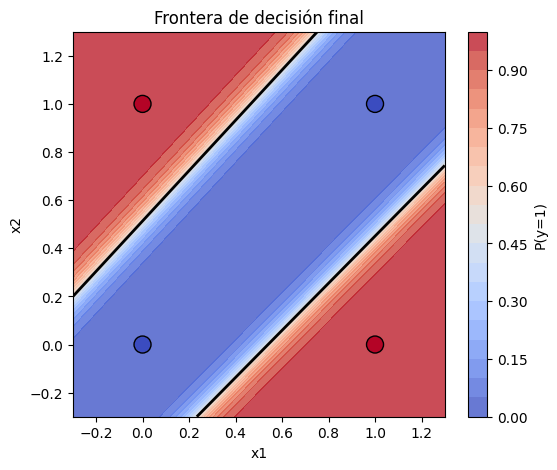

In [17]:
def plot_boundary(p, title='Frontera de decisión'):
    xx,yy=np.meshgrid(np.linspace(-.3,1.3,180),np.linspace(-.3,1.3,180))
    zz=forward(np.c_[xx.ravel(),yy.ravel()],p)['yh'].reshape(xx.shape)
    plt.figure(figsize=(6,5))
    plt.contourf(xx,yy,zz,levels=np.linspace(0,1,21),cmap='coolwarm',alpha=.8)
    plt.colorbar(label='P(y=1)')
    plt.contour(xx,yy,zz,levels=[.5],colors='black',linewidths=2)
    plt.scatter(X[:,0],X[:,1],c=y[:,0],cmap='coolwarm',edgecolor='black',s=150,vmin=0,vmax=1)
    plt.xlabel('x1');plt.ylabel('x2');plt.title(title);plt.show()
plot_boundary(p_final,'Frontera de decisión final')

## 7. Inspeccionar cualquier época

Si `ipywidgets` está instalado, el control permite retroceder y avanzar por las épocas guardadas. Si no está disponible, use `ver_epoca(1000)` o cualquier número entre 0 y 20000.

In [18]:
def ver_epoca(epoca=0):
    epoca=int(np.clip(epoca,0,len(history)-1))
    p=history[epoca]; pred=forward(X,p)['yh']
    print(f'Época {epoca}; Log Loss = {losses[epoca]:.6f}')
    display(pd.DataFrame(np.c_[X,y,pred],columns=['x1','x2','y','Probabilidad']).round(5))
    plot_boundary(p,f'Frontera en la época {epoca}')
try:
    import ipywidgets as widgets
    from ipywidgets import interact
    interact(ver_epoca,epoca=widgets.IntSlider(min=0,max=len(history)-1,step=250,value=0,
                                              description='Época',continuous_update=False))
except ImportError:
    print('Instale ipywidgets para habilitar el deslizador; se muestra la época 0.')
    ver_epoca(0)

interactive(children=(IntSlider(value=0, continuous_update=False, description='Época', max=2000, step=250), Ou…

## 8. Activaciones internas para cada patrón

In [19]:
cf=forward(X,p_final)
display(pd.DataFrame(np.c_[X,cf['z1'],cf['h'],cf['z2'],cf['yh']],
    columns=['x1','x2','z_h1','z_h2','h1','h2','z_salida','P(y=1)']).round(5))
print('W1 final:\n',p_final['W1'],'\nb1 final:',p_final['b1'])
print('W2 final:\n',p_final['W2'],'\nb2 final:',p_final['b2'])

,x1,x2,z_h1,z_h2,h1,h2,z_salida,P(y=1)
0,0.0,0.0,3.18328,-3.66886,0.96020,0.02487,-5.24515,0.00525
1,0.0,1.0,-3.23129,-10.65621,0.03800,0.00002,4.92619,0.99280
2,1.0,0.0,9.89422,3.17454,0.99995,0.95986,5.34038,0.99523
3,1.0,1.0,3.47964,-3.81281,0.97010,0.02161,-5.39603,0.00451


W1 final:
 [[ 6.710939  6.843398]
 [-6.414577 -6.987347]] 
b1 final: [[ 3.183282 -3.668863]]
W2 final:
 [[-11.347535]
 [ 11.803923]] 
b2 final: [[5.357176]]


## 9. Actividades para los estudiantes

1. Repita manualmente el cálculo de $h_1$, $h_2$, $\hat y$ y $L$ para el patrón $(0,1)$.
2. Verifique por qué los gradientes de los pesos asociados a $x_1$ son cero en esa observación.
3. Cambie la tasa de aprendizaje a 0.1 y compare la rapidez de convergencia.
4. Cambie la semilla de inicialización. ¿Todas las ejecuciones convergen al mismo ritmo?
5. Observe las épocas 0, 250, 1000, 5000 y 20000. Describa cómo cambia la frontera de decisión.
6. Compare **Log Loss** con **Brier Score**, definido como $rac{1}{m}\sum_i(\hat y_i-y_i)^2$.
7. Sustituya la actualización por lotes por SGD (una actualización por patrón) y compare las curvas de pérdida.

**Nota didáctica:** los pesos internos no tienen una interpretación única; diferentes inicializaciones pueden aprender la misma función XOR con pesos distintos. Una clasificación correcta no implica que las probabilidades sean exactamente 0 o 1.

In [20]:
brier = np.mean((result-y)**2)
print(f'Log Loss final: {log_loss(y,result):.8f}')
print(f'Brier Score final: {brier:.8f}')

Log Loss final: 0.00544848
Brier Score final: 0.00003063
